1. Завантаження та первинний аналіз даних

На цьому етапі ми завантажуємо датасет (який містить класи human та ai), очищаємо його від дублікатів та порожніх рядків, рахуємо довжину текстів та будуємо графіки розподілу.

Баланс класів після очищення:
 label
human    1334
ai        666
Name: count, dtype: int64


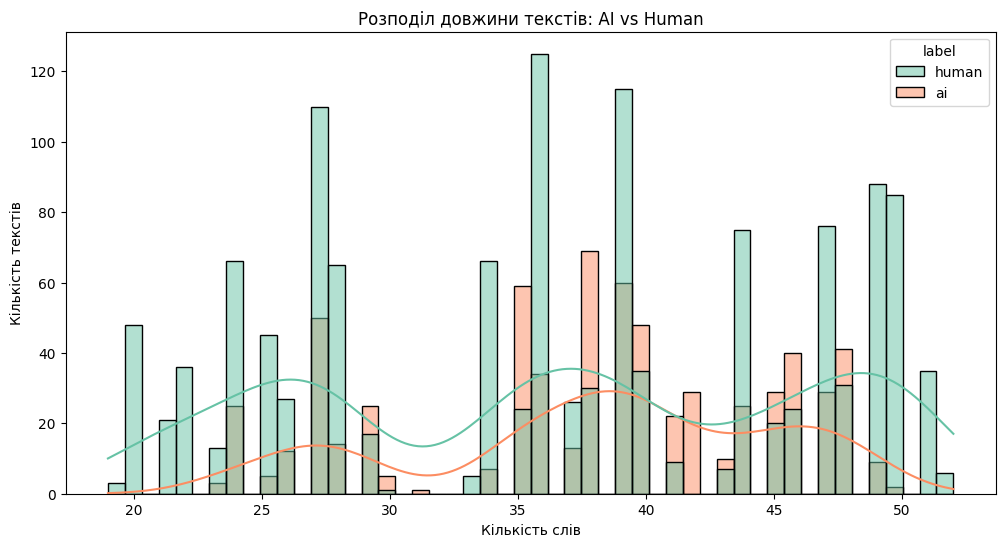

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Завантажуємо дані
df = pd.read_csv('ai_human_text.csv')

# Видаляємо дублікати та пропуски
df.drop_duplicates(inplace=True)
df.dropna(subset=['text_content'], inplace=True)

# Рахуємо довжину текстів
df['text_length'] = df['text_content'].apply(lambda x: len(str(x).split()))

# Фільтруємо занадто короткі тексти (відписки)
df = df[df['text_length'] > 10].copy()

print("Баланс класів після очищення:\n", df['label'].value_counts())

# Гістограма розподілу довжин
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='text_length', hue='label', bins=50, kde=True, palette='Set2')
plt.title('Розподіл довжини текстів: AI vs Human')
plt.xlabel('Кількість слів')
plt.ylabel('Кількість текстів')
plt.show()

Цей код готує дані до роботи та виводить графік, на якому ви побачите, чи є суттєва різниця у довжині між текстами, написаними людиною та згенерованими ШІ.

2. Попередня обробка тексту (Spacy)

Ми використовуємо Spacy для лематизації, видалення стоп-слів та пунктуації, зведення до нижнього регістру. Використовується nlp.pipe для швидкої пакетної обробки.

In [10]:
import spacy
from tqdm import tqdm

nlp = spacy.load("en_core_web_sm")

def preprocess_texts(texts):
    processed = []
    # Використання nlp.pipe для батчування та прискорення
    for doc in tqdm(nlp.pipe(texts, batch_size=100), total=len(texts)):
        tokens = [token.lemma_.lower() for token in doc if token.is_alpha and not token.is_stop]
        processed.append(tokens)
    return processed

# Застосовуємо пайплайн
df['processed_tokens'] = preprocess_texts(df['text_content'].tolist())

100%|██████████| 2000/2000 [00:12<00:00, 165.66it/s]


Метод is_alpha відкидає цифри та розділові знаки, is_stop відкидає загальновживані слова (the, is, at), а lemma_.lower() зводить слова до базової форми в нижньому регістрі

3. Навчання FastText моделі

FastText будує вектори слів на основі символьних n-грам, що вирішує проблему невідомих слів (Out-Of-Vocabulary).

In [11]:
from gensim.models import FastText

corpus = df['processed_tokens'].tolist()

model = FastText(
    sentences=corpus,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1, 
    workers=4,
    seed=42
)
print("Модель FastText успішно навчена!")

Модель FastText успішно навчена!


Ми створюємо векторний простір розмірністю 100 (vector_size=100), де кожне слово має свій вектор, згенерований за алгоритмом Skip-gram (sg=1).

4. Векторизація документів

Тут ми створюємо вектори для цілих текстів двома методами: простим усередненням (Mean Pooling) та зваженим за TF-IDF.

In [12]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# НОВЕ: max_df=0.85 відріже слова, які формують шаблонний каркас
vectorizer = TfidfVectorizer(min_df=2, max_df=0.85)
corpus_strings = [' '.join(tokens) for tokens in df['processed_tokens']]
vectorizer.fit(corpus_strings)
idf_dict = dict(zip(vectorizer.get_feature_names_out(), vectorizer.idf_))

def mean_pooling(tokens, model):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

def tfidf_weighted_pooling(tokens, model, tfidf_scores):
    vectors, weights = [], []
    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])
    if not vectors:
        return np.zeros(model.vector_size)
    weights = np.array(weights)
    weights = weights / weights.sum()
    return np.average(vectors, axis=0, weights=weights)

X_mean = np.array([mean_pooling(tokens, model) for tokens in df['processed_tokens']])
X_tfidf = np.array([tfidf_weighted_pooling(tokens, model, idf_dict) for tokens in df['processed_tokens']])

y = df['label'].astype(str).str.lower().map({'ai': 1, 'human': 0}).values

У mean_pooling всі слова мають однакову вагу. У tfidf_weighted_pooling специфічні, рідкісні слова отримують більшу вагу в підсумковому векторі тексту.

5. Навчання та оцінка класифікаторів

Ми тренуємо 3 моделі (SVM, LogReg, KNN) на обох типах агрегації та порівнюємо метрики

--- Оцінка Mean Pooling ---


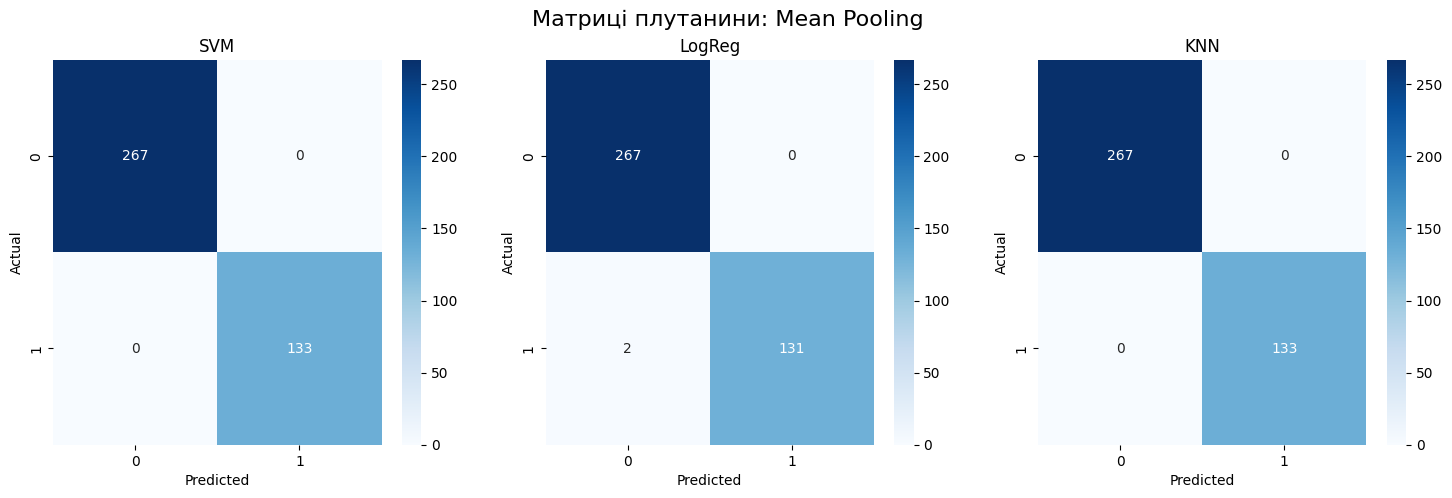

 Model  Accuracy  Macro F1  Balanced Acc  ROC AUC
   SVM     1.000  1.000000      1.000000      1.0
LogReg     0.995  0.994346      0.992481      1.0
   KNN     1.000  1.000000      1.000000      1.0

--- Оцінка TF-IDF Weighted ---


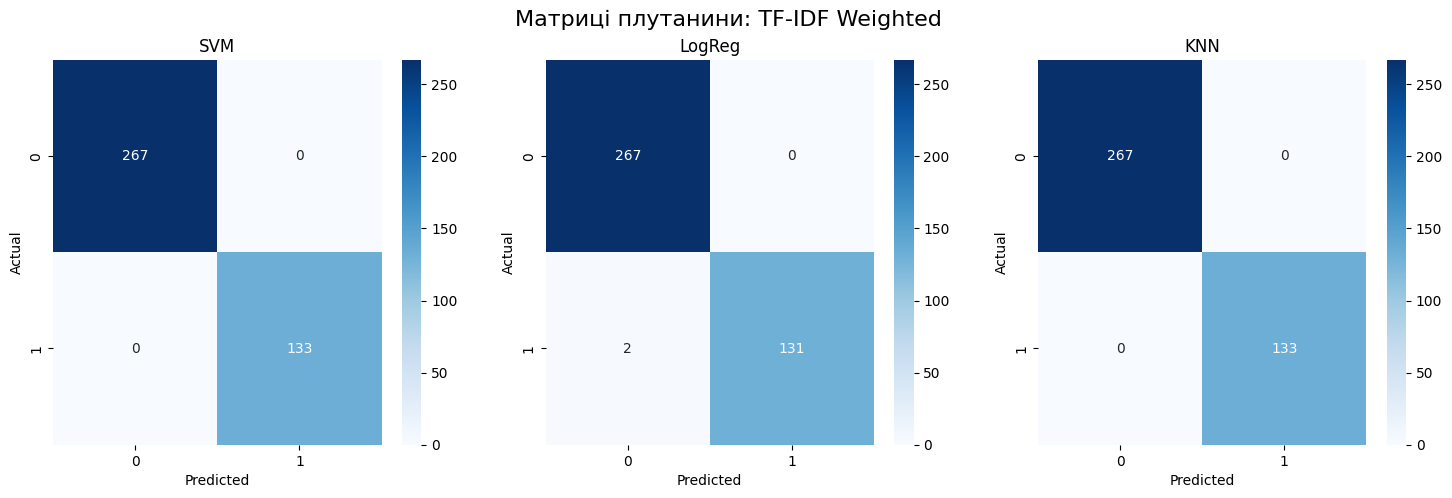

 Model  Accuracy  Macro F1  Balanced Acc  ROC AUC
   SVM     1.000  1.000000      1.000000      1.0
LogReg     0.995  0.994346      0.992481      1.0
   KNN     1.000  1.000000      1.000000      1.0


In [13]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score, confusion_matrix

# НОВЕ: Застосовуємо класичну регуляризацію (C=0.5) для запобігання overfitting'у
classifiers = {
    'SVM': SVC(kernel='linear', probability=True, C=0.5, random_state=42),
    'LogReg': LogisticRegression(max_iter=1000, C=0.5, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=7) # Збільшили кількість сусідів для згладжування
}

def evaluate_models(X, y, title):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    
    results = []
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Матриці плутанини: {title}', fontsize=16)

    for idx, (name, clf) in enumerate(classifiers.items()):
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_prob = clf.predict_proba(X_test)[:, 1] if hasattr(clf, "predict_proba") else [0]*len(y_test)
        
        results.append({
            'Model': name,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Macro F1': f1_score(y_test, y_pred, average='macro'),
            'Balanced Acc': balanced_accuracy_score(y_test, y_pred),
            'ROC AUC': roc_auc_score(y_test, y_prob)
        })
        
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx])
        axes[idx].set_title(name)
        axes[idx].set_xlabel('Predicted')
        axes[idx].set_ylabel('Actual')
        
    plt.show()
    return pd.DataFrame(results)

print("--- Оцінка Mean Pooling ---")
res_mean = evaluate_models(X_mean, y, "Mean Pooling")
print(res_mean.to_string(index=False))

print("\n--- Оцінка TF-IDF Weighted ---")
res_tfidf = evaluate_models(X_tfidf, y, "TF-IDF Weighted")
print(res_tfidf.to_string(index=False))

Цей блок виведе дві таблиці з метриками та 6 графіків (матриць плутанини), які покажуть, скільки текстів класифікатор вгадав правильно, а де помилився.

6. Візуалізація та аналіз (UMAP) та пошук маркерів ШІ

Ми проектуємо 100-вимірні вектори у 2D-простір для візуального аналізу.

/Users/taras/Documents/LNU_4(1)/машинне навчання/labs/lab_3/venv/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


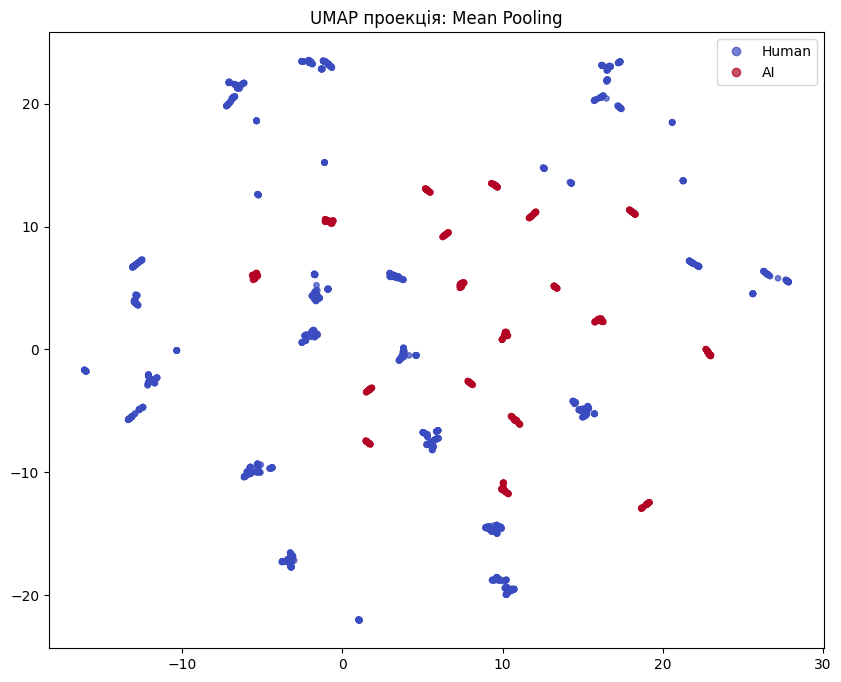

/Users/taras/Documents/LNU_4(1)/машинне навчання/labs/lab_3/venv/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


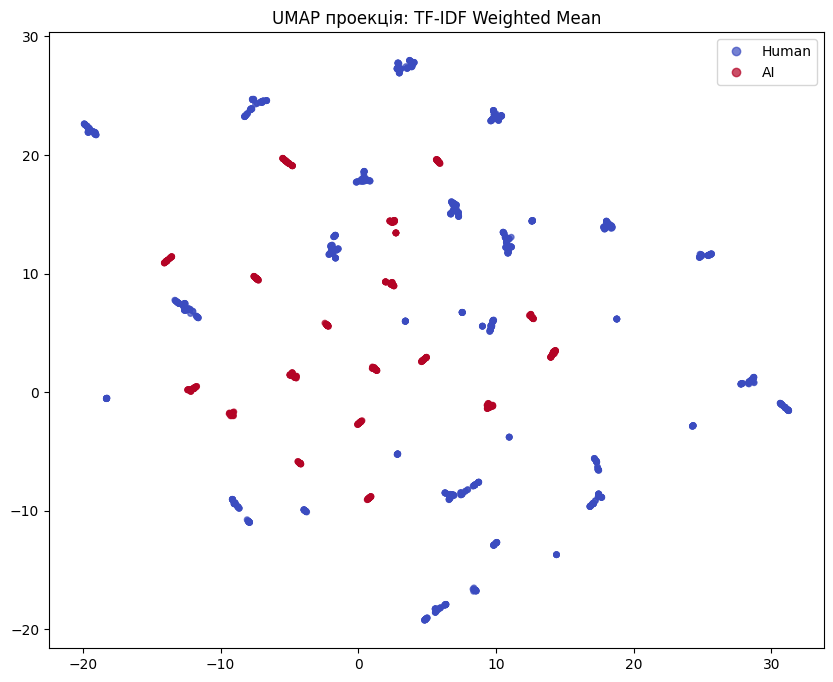


--- Топ-20 слів з найвищим IDF (специфічні маркери) ---
[('data', 7.502790045915623), ('contested', 7.215107973463843), ('breaking', 6.809642865355678), ('monday', 5.893352133481524), ('thursday', 5.828813612343952), ('friday', 5.768188990527517), ('tuesday', 5.768188990527517), ('wednesday', 5.556879896860311), ('editing', 5.510359881225417), ('comparative', 5.23410650459726), ('consultation', 5.23410650459726), ('equip', 5.23410650459726), ('failure', 5.23410650459726), ('good', 5.23410650459726), ('governance', 5.23410650459726), ('ground', 5.23410650459726), ('ill', 5.23410650459726), ('jurisdiction', 5.23410650459726), ('regulatory', 5.23410650459726), ('unique', 5.23410650459726)]


In [14]:
import umap

def plot_umap(X, y, title):
    reducer = umap.UMAP(random_state=42)
    embedding = reducer.fit_transform(X)
    
    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(embedding[:, 0], embedding[:, 1], c=y, cmap='coolwarm', s=15, alpha=0.7)
    plt.title(f'UMAP проекція: {title}')
    plt.legend(handles=scatter.legend_elements()[0], labels=['Human', 'AI'])
    plt.show()

plot_umap(X_mean, y, "Mean Pooling")
plot_umap(X_tfidf, y, "TF-IDF Weighted Mean")

print("\n--- Топ-20 слів з найвищим IDF (специфічні маркери) ---")
sorted_idf = sorted(idf_dict.items(), key=lambda item: item[1], reverse=True)
print(sorted_idf[:20])